In [15]:

import sqlite3
import pandas as pd
from IPython.display import display, HTML

# 1. Connexion m3a la base de données
conn = sqlite3.connect('UsinePlastique.db')
cursor = conn.cursor()

# 2. Création dyal les tables
cursor.executescript('''
CREATE TABLE IF NOT EXISTS Processus_Production (
    Etape TEXT NOT NULL,
    Description TEXT,
    Darija_Notes TEXT
);

CREATE TABLE IF NOT EXISTS Zones_Annexes (
    Zone TEXT NOT NULL,
    Fonction TEXT,
    Darija_Notes TEXT
);
''')

# Vider les tables bach ila runniti lcode bzaf d lmarat mayt3awdoch
cursor.executescript('''
DELETE FROM Processus_Production;
DELETE FROM Zones_Annexes;
''')

# 3. Les données
processus_data = [
    ('1. Stock Matière Première', 'Stockage PE et dosage selon OF.', 'Kaydiro l-3barat w kaykharjo l-OF.'),
    ('2. Extrusion', 'Fusion et soufflage (Films/Gaines).', 'Kaydoubo la matière w kaynfkhoha.'),
    ('3. Impression', 'Impression flexographique (6 machines).', 'Spectrophotomètre: Delta E <= 2-3.'),
    ('4. Complexe', 'Lamination couches (PE, OPP, PET).', 'Kayls9o mabin les couches 3la hsb l-OF.'),
    ('5. Soudure & Façonnage', 'Découpe et soudure (14 machines).', 'Kola machine katsayb forme dyal mika.')
]

zones_data = [
    ('Station d\'Encre', 'Dosage et mélange auto des encres.', 'Station d-encrage automatique.'),
    ('Logistique & Expédition', 'Stockage et livraison.', 'Fin kay3mro lmntoj n-nihayi.'),
    ('Zone Non-Conforme', 'Gestion des retours (Fiche Jaune/Rouge).', 'Fiche Jaune = Traitement, Rouge = Recyclage direct.'),
    ('Recyclage & Broyage', 'Broyage déchets plastiques.', 'Kaytthno les déchets BACH yrj3o l Extrusion.')
]

cursor.executemany('INSERT INTO Processus_Production (Etape, Description, Darija_Notes) VALUES (?, ?, ?)', processus_data)
cursor.executemany('INSERT INTO Zones_Annexes (Zone, Fonction, Darija_Notes) VALUES (?, ?, ?)', zones_data)
conn.commit()

# 4. Njibo les données
df_processus = pd.read_sql_query("SELECT * FROM Processus_Production", conn)
df_zones = pd.read_sql_query("SELECT * FROM Zones_Annexes", conn)
conn.close()

# 5. Affichage zwin f Colab (Color updated to Purple)
display(HTML("<h3 style='color: #800080;'> 1. PROCESSUS DE PRODUCTION</h3>"))
display(df_processus)

display(HTML("<br><h3 style='color: #800080;'> 2. ZONES ANNEXES</h3>"))
display(df_zones)

,Etape,Description,Darija_Notes
0,1. Stock Matière Première,Stockage PE et dosage selon OF.,Kaydiro l-3barat w kaykharjo l-OF.
1,2. Extrusion,Fusion et soufflage (Films/Gaines).,Kaydoubo la matière w kaynfkhoha.
2,3. Impression,Impression flexographique (6 machines).,Spectrophotomètre: Delta E <= 2-3.
3,4. Complexe,"Lamination couches (PE, OPP, PET).",Kayls9o mabin les couches 3la hsb l-OF.
4,5. Soudure & Façonnage,Découpe et soudure (14 machines).,Kola machine katsayb forme dyal mika.


,Zone,Fonction,Darija_Notes
0,Station d'Encre,Dosage et mélange auto des encres.,Station d-encrage automatique.
1,Logistique & Expédition,Stockage et livraison.,Fin kay3mro lmntoj n-nihayi.
2,Zone Non-Conforme,Gestion des retours (Fiche Jaune/Rouge).,"Fiche Jaune = Traitement, Rouge = Recyclage di..."
3,Recyclage & Broyage,Broyage déchets plastiques.,Kaytthno les déchets BACH yrj3o l Extrusion.


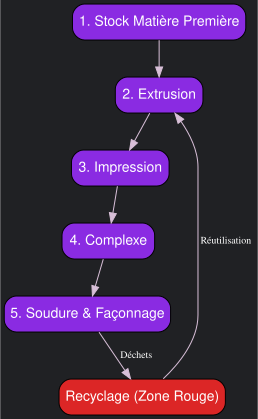

'Diagramme_Processus_Usine.png'

In [14]:
from graphviz import Digraph
from IPython.display import display

# 1. Création dyal l-Graphe (UML Activity Diagram)
dot = Digraph('Processus_Usine', format='png')

# 2. Design (Dark Mode + Purple theme)
dot.attr(bgcolor='#202124')
dot.attr('node', shape='box', style='filled,rounded', fillcolor='#8a2be2', fontcolor='white', fontname='Helvetica')
dot.attr('edge', color='#d8bfd8', fontcolor='white', fontsize='10')

# 3. Les Etapes (Noeuds)
dot.node('A', '1. Stock Matière Première')
dot.node('B', '2. Extrusion')
dot.node('C', '3. Impression')
dot.node('D', '4. Complexe')
dot.node('E', '5. Soudure & Façonnage')
dot.node('R', 'Recyclage (Zone Rouge)', fillcolor='#dc2626') # Red node

# 4. Les Flèches (Edges)
dot.edge('A', 'B')
dot.edge('B', 'C')
dot.edge('C', 'D')
dot.edge('D', 'E')
dot.edge('E', 'R', label=' Déchets')
dot.edge('R', 'B', label=' Réutilisation') # Dawra dyal recyclage

# 5. Affichage f Colab
display(dot)

# Enregistrer le diagramme f-Colab k-image PNG
dot.render('Diagramme_Processus_Usine', format='png', cleanup=True)